<a href="https://colab.research.google.com/github/TASRUNNER2010/Hackathon/blob/main/Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
import pandas as pd
from pathlib import Path

# Locate the folder containing all four original EPA files.
folder = Path(
    "/content/drive/MyDrive/veritas AI project"
)

# List only the original files so we don't accidentally load cleaned outputs.
filenames = [
    "2023_ad_viz_plotval_data.csv",
    "2024_ad_viz_plotval_data.csv",
    "2025_ad_viz_plotval_data.csv",
    "2026_ad_viz_plotval_data.csv"
]

# Read each file and preserve identifiers as text.
tables = []

for filename in filenames:
    table = pd.read_csv(
        folder / filename,
        dtype={"Site ID": "string", "POC": "string"}
    )

    # Remove surrounding spaces from column names.
    table.columns = table.columns.str.strip()

    # Record which file each measurement came from.
    table["source_file"] = filename
    tables.append(table)

# Combine the years and preserve an independent raw copy.
raw_df = pd.concat(tables, ignore_index=True)

# Select the Rutgers station and its mostly daily POC 3 series.
df = raw_df.loc[
    raw_df["Site ID"].str.strip().eq("340230011")
    & raw_df["POC"].str.strip().eq("3")
].copy()

# Stop if the expected station and instrument were not found.
if df.empty:
    raise ValueError("No records found for Rutgers POC 3.")

# Keep measurements and metadata useful for checking data quality.
df = df[[
    "Date",
    "Daily Mean PM2.5 Concentration",
    "Daily AQI Value",
    "Source",
    "Method Code",
    "Method Description",
    "source_file"
]].rename(columns={
    "Date": "date",
    "Daily Mean PM2.5 Concentration": "pm25",
    "Daily AQI Value": "aqi",
    "Source": "source",
    "Method Code": "method_code",
    "Method Description": "method_description"
})

# Convert date strings into dates and measurements into numbers.
df["date"] = pd.to_datetime(
    df["date"], format="%m/%d/%Y", errors="raise"
)

for column in ["pm25", "aqi"]:
    df[column] = pd.to_numeric(df[column], errors="raise")

# Remove repeated records, ignoring the filename when comparing rows.
record_columns = [c for c in df.columns if c != "source_file"]
df = df.drop_duplicates(subset=record_columns)

# Investigate conflicting same-day records rather than choosing arbitrarily.
if df["date"].duplicated().any():
    raise ValueError("Multiple different records exist for the same date.")

# Build a complete calendar from the actual selected date range.
# This replaces the old calendar that was restricted to 2023.
calendar = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    name="date"
)

# Insert missing dates without inventing pollution measurements.
df = (
    df.set_index("date")
      .sort_index()
      .reindex(calendar)
      .reset_index()
)

# Flag missing pollution measurements and preliminary AirNow records.
df["measurement_missing"] = df["pm25"].isna()
df["is_airnow"] = df["source"].eq("AirNow")

# Summarize measurement coverage separately for each year.
summary = df.groupby(df["date"].dt.year).agg(
    calendar_days=("date", "size"),
    measured_days=("pm25", "count"),
    missing_days=("measurement_missing", "sum"),
    airnow_records=("is_airnow", "sum")
)

display(summary)
display(df.head())

# Save a new combined file without overwriting any original CSV.
df.to_csv(folder / "airaware_epa_clean_daily_2023_2026.csv", index=False)

,calendar_days,measured_days,missing_days,airnow_records
date,,,,
2023,365,337,28,0
2024,366,348,18,0
2025,365,354,11,0
2026,317,292,25,130


,date,pm25,aqi,source,method_code,method_description,source_file,measurement_missing,is_airnow
0,2023-01-01,5.6,31.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False
1,2023-01-02,9.9,52.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False
2,2023-01-03,15.3,63.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False
3,2023-01-04,12.3,57.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False
4,2023-01-05,12.5,57.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False


In [25]:
import requests

# Use the first and last dates in the cleaned EPA dataset.
# strftime converts dates into the format Open-Meteo expects.
start_date = df["date"].min().strftime("%Y-%m-%d")
end_date = df["date"].max().strftime("%Y-%m-%d")

# Open-Meteo's historical weather API.
url = "https://archive-api.open-meteo.com/v1/archive"

# Specify the location, date range, weather variables, and units.
params = {
    # Coordinates of the Rutgers EPA monitoring station.
    "latitude": 40.462182,
    "longitude": -74.429439,

    # Match the full date range of the cleaned EPA data.
    "start_date": start_date,
    "end_date": end_date,

    # Daily average temperature, humidity, and wind speed,
    # plus total daily precipitation.
    "daily": ",".join([
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean"
    ]),

    # Match weather days to local New Jersey calendar days.
    "timezone": "America/New_York",

    # Request explicit measurement units.
    "temperature_unit": "celsius",
    "precipitation_unit": "mm",
    "wind_speed_unit": "ms"
}

# Download the weather data.
# Stop if Open-Meteo returns an HTTP error.
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

# Convert the response from JSON into a daily weather table.
weather_data = response.json()
weather = pd.DataFrame(weather_data["daily"])

# Shorten column names and include units in their names.
weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temperature_c",
    "relative_humidity_2m_mean": "humidity_pct",
    "precipitation_sum": "precipitation_mm",
    "wind_speed_10m_mean": "wind_speed_ms"
})

# Convert weather date strings into pandas dates.
weather["date"] = pd.to_datetime(weather["date"])

# Ensure weather values are numeric.
weather_columns = [
    "temperature_c",
    "humidity_pct",
    "precipitation_mm",
    "wind_speed_ms"
]

for column in weather_columns:
    weather[column] = pd.to_numeric(weather[column], errors="raise")

# Match weather and pollution records by date.
# Preserve every EPA calendar day, including missing measurements.
# Stop if either table has duplicate dates.
combined = df.merge(
    weather,
    on="date",
    how="left",
    validate="one_to_one"
).sort_values("date").reset_index(drop=True)

# Report the requested period and missing weather values.
print(f"Requested weather: {start_date} to {end_date}")
print("Missing weather values:")
print(combined[weather_columns].isna().sum())

# Show a sample of the merged pollution-and-weather dataset.
display(combined.head(10))

# Save weather separately so it can be reused without another download.
weather.to_csv(
    folder / "airaware_weather_2023_2026.csv",
    index=False
)

# Save the complete merged dataset without overwriting the EPA-only file.
combined.to_csv(
    folder / "airaware_epa_weather_2023_2026.csv",
    index=False
)

Requested weather: 2023-01-01 to 2026-11-13
Missing weather values:
temperature_c       0
humidity_pct        0
precipitation_mm    0
wind_speed_ms       0
dtype: int64


,date,pm25,aqi,source,method_code,method_description,source_file,measurement_missing,is_airnow,temperature_c,humidity_pct,precipitation_mm,wind_speed_ms
0,2023-01-01,5.6,31.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,9.5,83,0.8,3.24
1,2023-01-02,9.9,52.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,9.2,83,0.8,1.67
2,2023-01-03,15.3,63.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,11.2,94,6.2,2.36
3,2023-01-04,12.3,57.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,15.0,91,2.1,2.64
4,2023-01-05,12.5,57.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,11.3,92,0.0,2.41
5,2023-01-06,NaN,NaN,NaN,NaN,NaN,NaN,True,False,6.6,84,6.9,2.93
6,2023-01-07,NaN,NaN,NaN,NaN,NaN,NaN,True,False,3.8,68,0.0,3.59
7,2023-01-08,NaN,NaN,NaN,NaN,NaN,NaN,True,False,1.6,71,0.0,1.97
8,2023-01-09,NaN,NaN,NaN,NaN,NaN,NaN,True,False,3.5,75,1.7,2.83
9,2023-01-10,13.5,59.0,AQS,183.0,Thermo Scientific 5014i or FH62C14-DHS w/VSCC,2023_ad_viz_plotval_data.csv,False,False,2.8,68,0.0,2.58


In [26]:
# Work on a separate copy of the complete daily calendar.
forecast_data = combined.sort_values("date").copy()

# Use the following calendar day's PM2.5 as the prediction target.
forecast_data["pm25_tomorrow"] = forecast_data["pm25"].shift(-1)

# Record the date being predicted so we can split by target date.
forecast_data["target_date"] = (
    forecast_data["date"] + pd.Timedelta(days=1)
)

# Start with today's pollution and today's weather as inputs.
features = [
    "pm25",
    "temperature_c",
    "humidity_pct",
    "precipitation_mm",
    "wind_speed_ms"
]

# Keep only examples with complete inputs and a real next-day measurement.
# Missing pollution is never replaced with zero or an invented target.
model_df = forecast_data.dropna(
    subset=features + ["pm25_tomorrow"]
).copy()

# Split chronologically using the date being predicted.
train_df = model_df[
    model_df["target_date"] < "2025-01-01"
].copy()

validation_df = model_df[
    (model_df["target_date"] >= "2025-01-01")
    & (model_df["target_date"] < "2026-01-01")
].copy()

test_df = model_df[
    model_df["target_date"] >= "2026-01-01"
].copy()

# Check how many forecasting examples are available in each period.
print("Training examples:", len(train_df))
print("Validation examples:", len(validation_df))
print("Test examples:", len(test_df))

# Inspect the input date, target date, and actual next-day pollution.
display(model_df[
    ["date", "target_date", "pm25", "pm25_tomorrow"]
].head())

Training examples: 674
Validation examples: 350
Test examples: 285


,date,target_date,pm25,pm25_tomorrow
0,2023-01-01,2023-01-02,5.6,9.9
1,2023-01-02,2023-01-03,9.9,15.3
2,2023-01-03,2023-01-04,15.3,12.3
3,2023-01-04,2023-01-05,12.3,12.5
9,2023-01-10,2023-01-11,13.5,6.0


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Select the training inputs and the next-day measurements to learn from.
X_train = train_df[features]
y_train = train_df["pm25_tomorrow"]

# Create a Linear Regression model.
model = LinearRegression()

# Train the model using only the training period.
model.fit(X_train, y_train)

# Predict next-day pollution for the validation examples.
validation_predictions = model.predict(validation_df[features])

# Baseline: tomorrow's pollution equals today's pollution.
baseline_predictions = validation_df["pm25"]

# Get the actual next-day measurements for those same examples.
actual = validation_df["pm25_tomorrow"]

# Compare both approaches using mean absolute error.
baseline_mae = mean_absolute_error(actual, baseline_predictions)
model_mae = mean_absolute_error(actual, validation_predictions)

# Lower MAE means smaller prediction errors on average.
print(f"Validation baseline MAE: {baseline_mae:.2f} µg/m³")
print(f"Validation Linear Regression MAE: {model_mae:.2f} µg/m³")

Validation baseline MAE: 2.60 µg/m³
Validation Linear Regression MAE: 2.41 µg/m³


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Create Random Forest with the same settings as before.
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train Random Forest using only 2023–2024 examples.
# Your existing Linear Regression remains stored in "model".
rf_model.fit(
    train_df[features],
    train_df["pm25_tomorrow"]
)

# Save validation predictions for your existing graph code.
rf_predictions = rf_model.predict(validation_df[features])

# Collect performance results for both periods.
results = []

for period, data in [
    ("Training: 2023–2024", train_df),
    ("Validation: 2025", validation_df)
]:
    # Actual next-day measurements for this period.
    actual_values = data["pm25_tomorrow"]

    # Predict identical examples with each approach.
    predictions = {
        "Persistence baseline": data["pm25"],
        "Linear Regression": model.predict(data[features]),
        "Random Forest": rf_model.predict(data[features])
    }

    # Calculate the baseline error used for the improvement comparison.
    baseline_error = mean_absolute_error(
        actual_values, predictions["Persistence baseline"]
    )

    for name, predicted_values in predictions.items():
        # MAE measures average absolute error in pollution units.
        mae = mean_absolute_error(actual_values, predicted_values)

        # Positive improvement means lower MAE than persistence.
        # Leave undefined if the baseline already has zero error.
        improvement = (
            100 * (baseline_error - mae) / baseline_error
            if baseline_error > 0 else float("nan")
        )

        results.append({
            "Period": period,
            "Approach": name,
            "Examples": len(data),
            "MAE (µg/m³)": mae,
            "R²": r2_score(actual_values, predicted_values),
            "MAE improvement vs baseline (%)": improvement
        })

# Convert the collected scores into a readable table.
comparison = pd.DataFrame(results)

# Show training results to help investigate fitting behavior.
print("TRAINING PERFORMANCE")
display(
    comparison[
        comparison["Period"] == "Training: 2023–2024"
    ].reset_index(drop=True).round(3)
)

# Use validation results to compare and choose approaches.
print("VALIDATION PERFORMANCE")
display(
    comparison[
        comparison["Period"] == "Validation: 2025"
    ].reset_index(drop=True).round(3)
)

TRAINING PERFORMANCE


,Period,Approach,Examples,MAE (µg/m³),R²,MAE improvement vs baseline (%)
0,Training: 2023–2024,Persistence baseline,674,3.394,0.290,0.000
1,Training: 2023–2024,Linear Regression,674,2.890,0.436,14.862
2,Training: 2023–2024,Random Forest,674,2.621,0.515,22.775


VALIDATION PERFORMANCE


,Period,Approach,Examples,MAE (µg/m³),R²,MAE improvement vs baseline (%)
0,Validation: 2025,Persistence baseline,350,2.604,0.253,0.000
1,Validation: 2025,Linear Regression,350,2.410,0.432,7.457
2,Validation: 2025,Random Forest,350,2.346,0.347,9.918


In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

# Create Ridge Regression with feature scaling.
# Scaling prevents input units from affecting the penalty unfairly.
# Alpha controls penalty strength; 1.0 is our starting setting.
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train using only 2023–2024 examples.
# The scaler also learns its values from training data only.
# Your existing Linear Regression and Random Forest remain unchanged.
ridge_model.fit(
    train_df[features],
    train_df["pm25_tomorrow"]
)

# Save validation predictions for graphing.
ridge_predictions = ridge_model.predict(validation_df[features])

# Collect performance results for both periods.
results = []

for period, data in [
    ("Training: 2023–2024", train_df),
    ("Validation: 2025", validation_df)
]:
    # Actual next-day measurements for this period.
    actual_values = data["pm25_tomorrow"]

    # Predict identical examples with each approach.
    predictions = {
        "Persistence baseline": data["pm25"],
        "Linear Regression": model.predict(data[features]),
        "Random Forest": rf_model.predict(data[features]),
        "Ridge Regression": ridge_model.predict(data[features])
    }

    # Calculate baseline MAE for the improvement comparison.
    baseline_error = mean_absolute_error(
        actual_values, predictions["Persistence baseline"]
    )

    for name, predicted_values in predictions.items():
        # MAE measures average absolute error in pollution units.
        mae = mean_absolute_error(actual_values, predicted_values)

        # Positive improvement means lower MAE than persistence.
        # Leave undefined if the baseline already has zero error.
        improvement = (
            100 * (baseline_error - mae) / baseline_error
            if baseline_error > 0 else float("nan")
        )

        results.append({
            "Period": period,
            "Approach": name,
            "Examples": len(data),
            "MAE (µg/m³)": mae,
            "R²": r2_score(actual_values, predicted_values),
            "MAE improvement vs baseline (%)": improvement
        })

# Convert the collected scores into a readable table.
comparison = pd.DataFrame(results)

# Show training results to help investigate fitting behavior.
print("TRAINING PERFORMANCE")
display(
    comparison[
        comparison["Period"] == "Training: 2023–2024"
    ].reset_index(drop=True).round(3)
)

# Use validation results to compare approaches.
# The reserved 2026 test set is not used.
print("VALIDATION PERFORMANCE")
display(
    comparison[
        comparison["Period"] == "Validation: 2025"
    ].reset_index(drop=True).round(3)
)

TRAINING PERFORMANCE


,Period,Approach,Examples,MAE (µg/m³),R²,MAE improvement vs baseline (%)
0,Training: 2023–2024,Persistence baseline,674,3.394,0.290,0.000
1,Training: 2023–2024,Linear Regression,674,2.890,0.436,14.862
2,Training: 2023–2024,Random Forest,674,2.621,0.515,22.775
3,Training: 2023–2024,Ridge Regression,674,2.889,0.436,14.874


VALIDATION PERFORMANCE


,Period,Approach,Examples,MAE (µg/m³),R²,MAE improvement vs baseline (%)
0,Validation: 2025,Persistence baseline,350,2.604,0.253,0.000
1,Validation: 2025,Linear Regression,350,2.410,0.432,7.457
2,Validation: 2025,Random Forest,350,2.346,0.347,9.918
3,Validation: 2025,Ridge Regression,350,2.410,0.432,7.455


In [30]:
# Average predictions from the two existing trained models.
# This does not retrain either model.
lr_predictions = model.predict(validation_df[features])
rf_predictions = rf_model.predict(validation_df[features])

ensemble_predictions = (lr_predictions + rf_predictions) / 2

# Evaluate on the same 2025 validation examples.
actual_values = validation_df["pm25_tomorrow"]

print(
    "Ensemble validation MAE:",
    round(mean_absolute_error(actual_values, ensemble_predictions), 3)
)
print(
    "Ensemble validation R²:",
    round(r2_score(actual_values, ensemble_predictions), 3)
)

Ensemble validation MAE: 2.347
Ensemble validation R²: 0.419


In [38]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Copy the complete daily calendar, preserving missing dates.
history_data = (
    combined.sort_values("date")
    .reset_index(drop=True)
    .copy()
)

# Confirm that each row represents the next calendar day.
if not history_data["date"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all():
    raise ValueError("The dataset must contain every calendar day exactly once.")

# Add recent pollution history using only today and earlier dates.
history_data["pm25_yesterday"] = history_data["pm25"].shift(1)

history_data["pm25_mean_3days"] = (
    history_data["pm25"]
    .rolling(window=3, min_periods=3)
    .mean()
)

history_data["pm25_change"] = (
    history_data["pm25"] - history_data["pm25_yesterday"]
)

# Create tomorrow's target before removing incomplete rows.
history_data["pm25_tomorrow"] = history_data["pm25"].shift(-1)
history_data["target_date"] = (
    history_data["date"] + pd.Timedelta(days=1)
)

# Keep the original features and add history.
history_features = features + [
    "pm25_yesterday",
    "pm25_mean_3days",
    "pm25_change"
]

# Require all inputs and a real next-day target.
history_examples = history_data.dropna(
    subset=history_features + ["pm25_tomorrow"]
).copy()

# Keep the same chronological boundaries.
history_train = history_examples[
    history_examples["target_date"] < "2025-01-01"
].copy()

history_validation = history_examples[
    (history_examples["target_date"] >= "2025-01-01")
    & (history_examples["target_date"] < "2026-01-01")
].copy()

rf_settings = {
    "n_estimators": 300,
    "max_depth": 6,
    "min_samples_leaf": 5,
    "random_state": 42,
    "n_jobs": -1
}

# Train a control ensemble without history on the same training rows.
matched_lr = LinearRegression()
matched_rf = RandomForestRegressor(**rf_settings)

matched_lr.fit(
    history_train[features], history_train["pm25_tomorrow"]
)
matched_rf.fit(
    history_train[features], history_train["pm25_tomorrow"]
)

# Train both components of the new ensemble with history.
history_lr_model = LinearRegression()
history_rf_model = RandomForestRegressor(**rf_settings)

history_lr_model.fit(
    history_train[history_features],
    history_train["pm25_tomorrow"]
)
history_rf_model.fit(
    history_train[history_features],
    history_train["pm25_tomorrow"]
)

# Predict identical validation dates with the original ensemble.
original_ensemble_predictions = (
    model.predict(history_validation[features])
    + rf_model.predict(history_validation[features])
) / 2

# Predict with the control ensemble trained on matched rows.
matched_ensemble_predictions = (
    matched_lr.predict(history_validation[features])
    + matched_rf.predict(history_validation[features])
) / 2

# Average both history models to create the new ensemble prediction.
history_ensemble_predictions = (
    history_lr_model.predict(history_validation[history_features])
    + history_rf_model.predict(history_validation[history_features])
) / 2

# Compare all approaches on the same validation examples.
predictions = {
    "Persistence baseline": history_validation["pm25"],
    "Original ensemble": original_ensemble_predictions,
    "Matched-row ensemble without history": matched_ensemble_predictions,
    "Matched-row ensemble with history": history_ensemble_predictions
}

results = []

for name, predicted_values in predictions.items():
    results.append({
        "Approach": name,
        "Validation examples": len(history_validation),
        "MAE (µg/m³)": mean_absolute_error(
            history_validation["pm25_tomorrow"], predicted_values
        ),
        "R²": r2_score(
            history_validation["pm25_tomorrow"], predicted_values
        )
    })

print("History training examples:", len(history_train))
print("History validation examples:", len(history_validation))
display(pd.DataFrame(results).round(3))

History training examples: 652
History validation examples: 342


,Approach,Validation examples,MAE (µg/m³),R²
0,Persistence baseline,342,2.608,0.256
1,Original ensemble,342,2.347,0.422
2,Matched-row ensemble without history,342,2.340,0.410
3,Matched-row ensemble with history,342,2.270,0.456


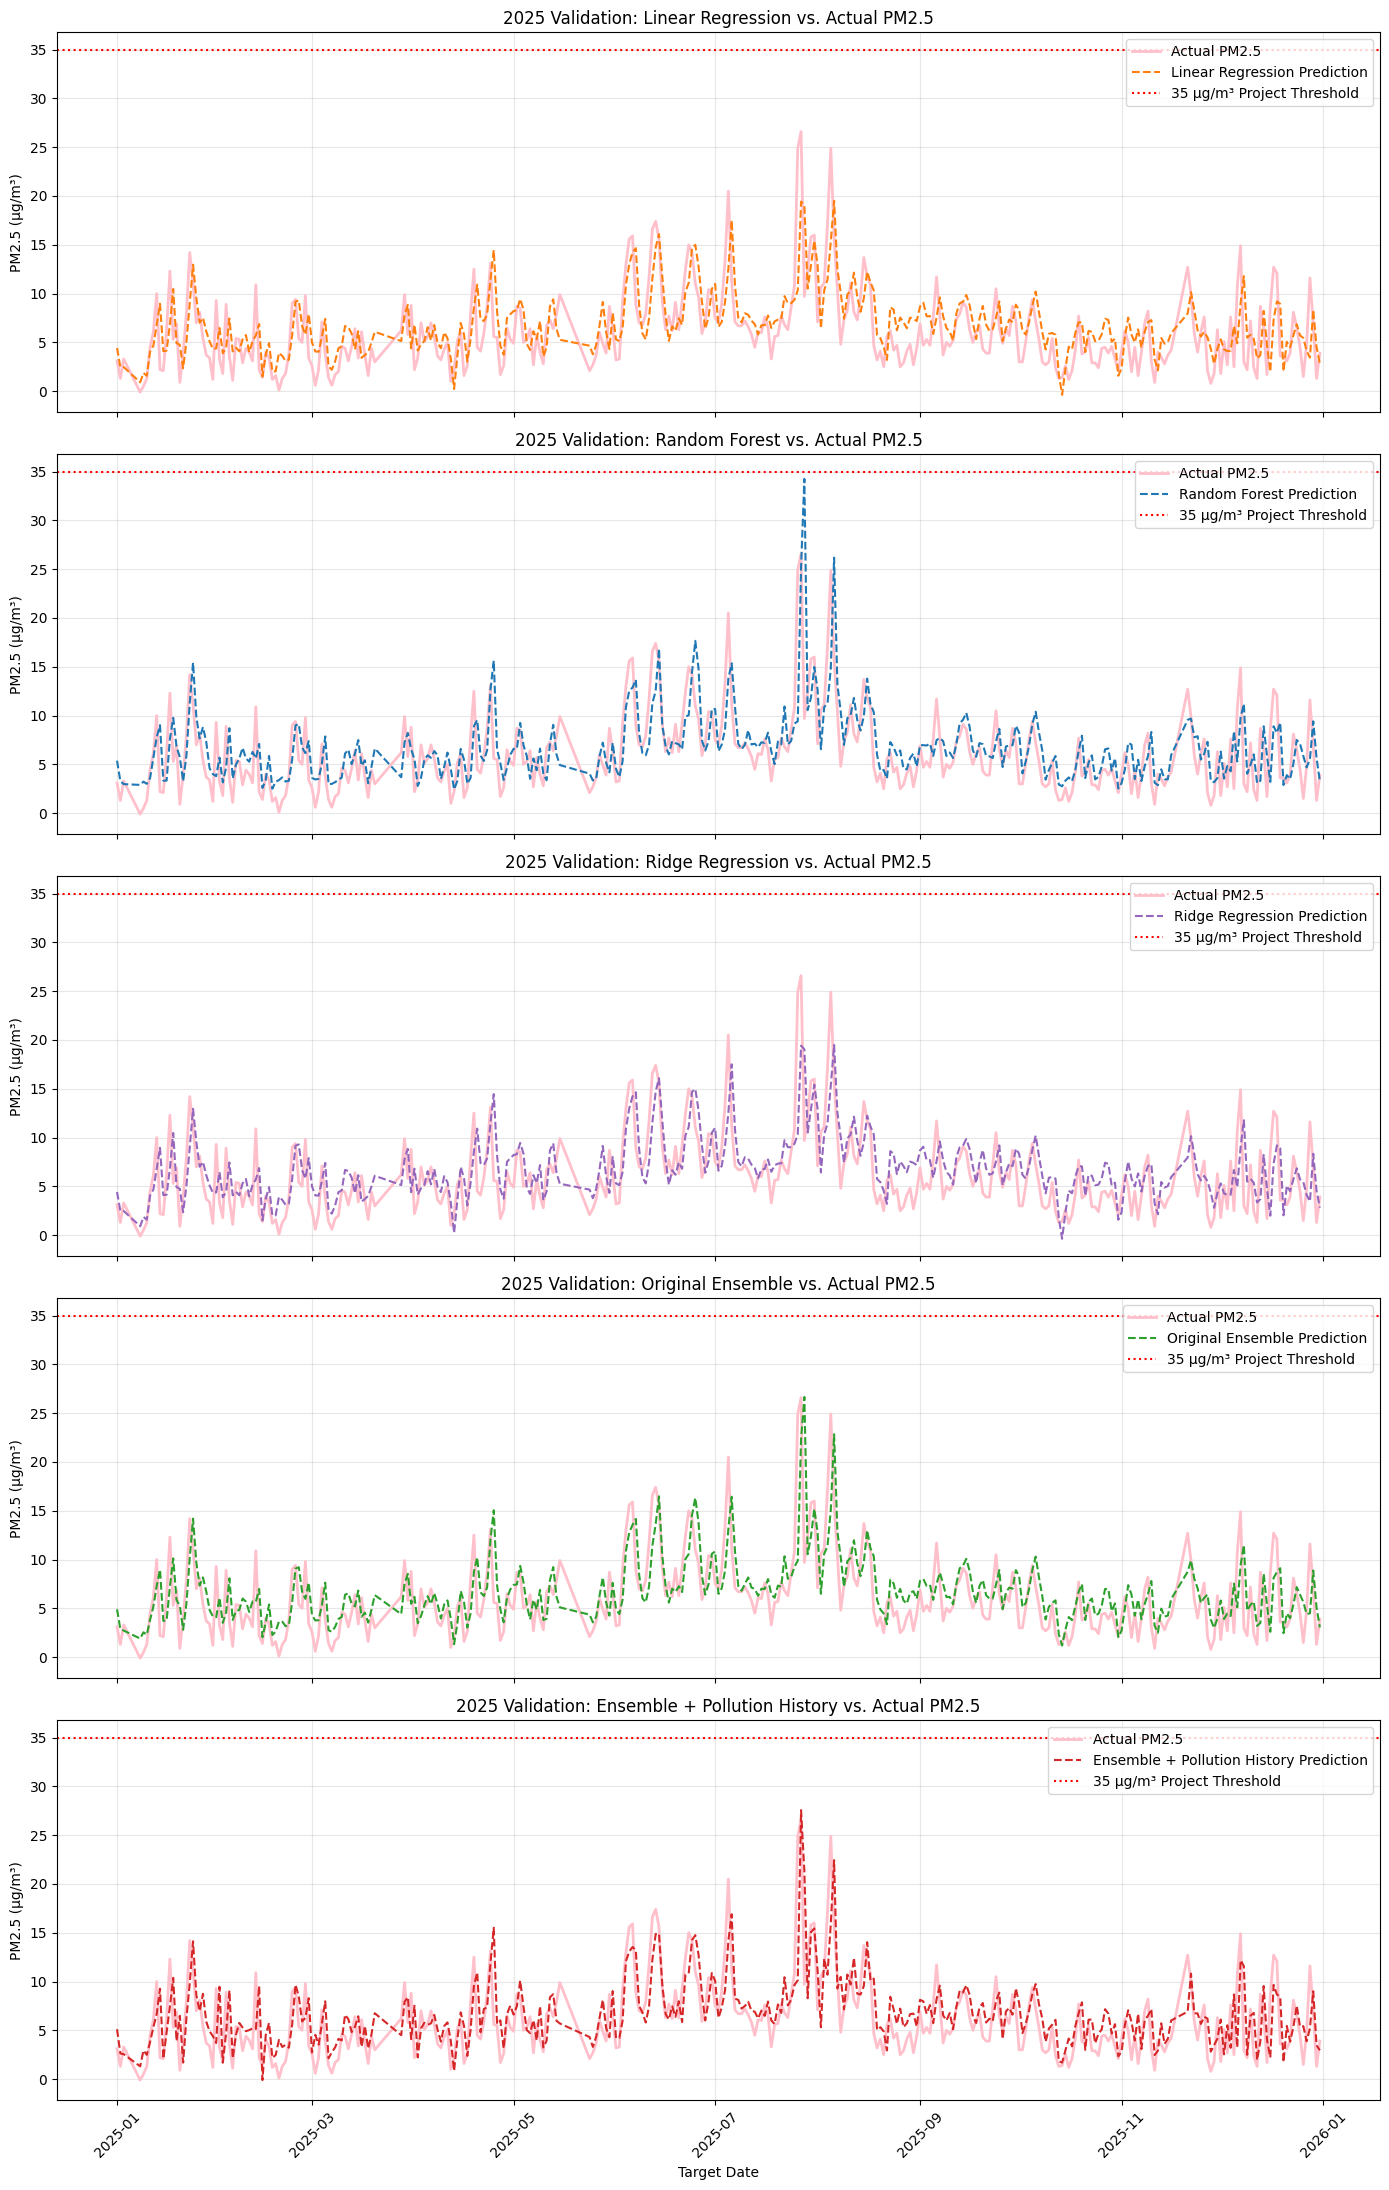

In [39]:
import matplotlib.pyplot as plt

# Use the same eligible dates for every model.
plot_data = history_validation.sort_values("target_date")

# Calculate original models' predictions on these dates.
lr_predictions = model.predict(plot_data[features])
rf_predictions = rf_model.predict(plot_data[features])
ridge_predictions = ridge_model.predict(plot_data[features])

# Original ensemble: average the original Linear Regression and Forest.
ensemble_predictions = (lr_predictions + rf_predictions) / 2

# History ensemble: both components use the expanded history features.
history_ensemble_predictions = (
    history_lr_model.predict(plot_data[history_features])
    + history_rf_model.predict(plot_data[history_features])
) / 2

# Specify each approach and its graph color.
models_to_plot = [
    ("Linear Regression", lr_predictions, "tab:orange"),
    ("Random Forest", rf_predictions, "tab:blue"),
    ("Ridge Regression", ridge_predictions, "tab:purple"),
    ("Original Ensemble", ensemble_predictions, "tab:green"),
    ("Ensemble + Pollution History", history_ensemble_predictions, "tab:red")
]

# Create one graph per approach with matching axes.
fig, axes = plt.subplots(
    len(models_to_plot), 1,
    figsize=(14, 22),
    sharex=True,
    sharey=True
)

for ax, (name, predictions, color) in zip(axes, models_to_plot):
    # Plot actual next-day measurements.
    ax.plot(
        plot_data["target_date"],
        plot_data["pm25_tomorrow"],
        label="Actual PM2.5",
        color="pink",
        linewidth=2
    )

    # Plot predictions for the same target dates.
    ax.plot(
        plot_data["target_date"],
        predictions,
        label=f"{name} Prediction",
        color=color,
        linewidth=1.5,
        linestyle="--"
    )

    # Show the illustrative project threshold.
    ax.axhline(
        y=35,
        color="red",
        linestyle=":",
        label="35 µg/m³ Project Threshold"
    )

    # Label each graph and add a legend and grid.
    ax.set_title(f"2025 Validation: {name} vs. Actual PM2.5")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Format the shared date axis.
axes[-1].set_xlabel("Target Date")
axes[-1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

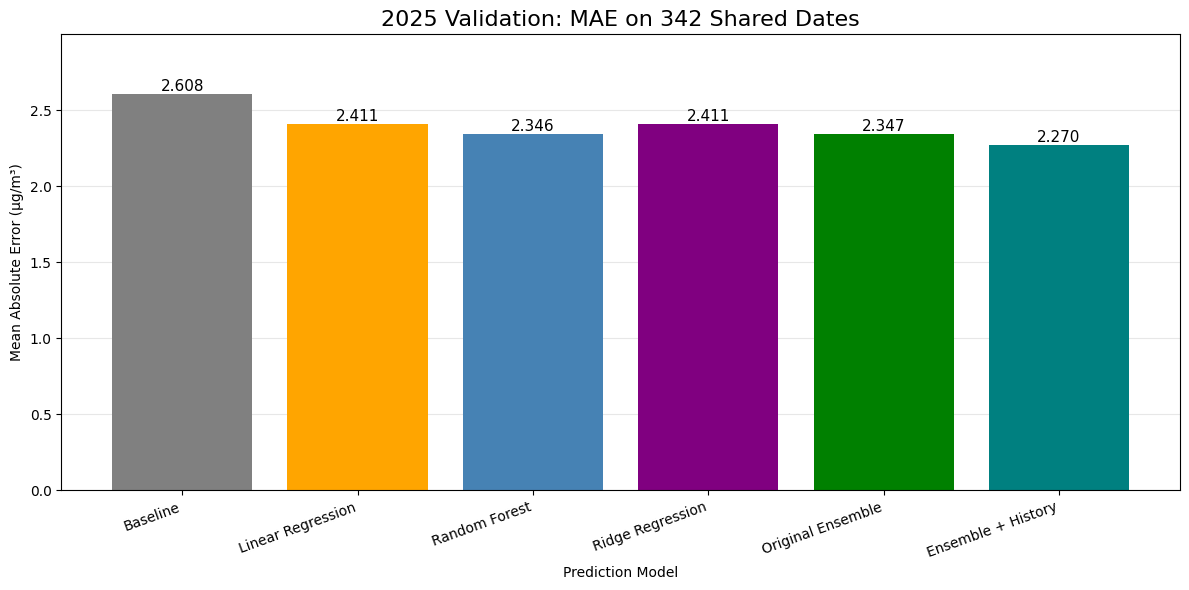


Validation MAE Ranking:
1. Ensemble + History: 2.270 µg/m³
2. Random Forest: 2.346 µg/m³
3. Original Ensemble: 2.347 µg/m³
4. Linear Regression: 2.411 µg/m³
5. Ridge Regression: 2.411 µg/m³
6. Baseline: 2.608 µg/m³


In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Use the same history-eligible validation examples for every approach.
comparison_data = history_validation.sort_values("target_date")
actual_values = comparison_data["pm25_tomorrow"]

# Calculate fresh predictions to avoid relying on earlier graph variables.
linear_predictions = model.predict(comparison_data[features])
forest_predictions = rf_model.predict(comparison_data[features])
ridge_predictions = ridge_model.predict(comparison_data[features])

# Original ensemble: average Linear Regression and Random Forest.
original_ensemble_predictions = (
    linear_predictions + forest_predictions
) / 2

# Improved ensemble: both models receive pollution-history features.
history_ensemble_predictions = (
    history_lr_model.predict(comparison_data[history_features])
    + history_rf_model.predict(comparison_data[history_features])
) / 2

# Store predictions for all approaches on identical validation dates.
predictions = {
    "Baseline": comparison_data["pm25"],
    "Linear Regression": linear_predictions,
    "Random Forest": forest_predictions,
    "Ridge Regression": ridge_predictions,
    "Original Ensemble": original_ensemble_predictions,
    "Ensemble + History": history_ensemble_predictions
}

# Calculate MAE for each approach.
models = list(predictions.keys())
errors = [
    mean_absolute_error(actual_values, predictions[name])
    for name in models
]

# Create the error comparison graph.
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    models,
    errors,
    color=[
        "gray",
        "orange",
        "steelblue",
        "purple",
        "green",
        "teal"
    ]
)

# Display MAE values above each bar.
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Label the graph and note the shared evaluation sample.
ax.set_title(
    f"2025 Validation: MAE on {len(comparison_data)} Shared Dates",
    fontsize=16
)
ax.set_xlabel("Prediction Model")
ax.set_ylabel("Mean Absolute Error (µg/m³)")
ax.set_ylim(0, max(errors) * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Rank approaches by validation MAE; lower is better.
ranking = sorted(zip(models, errors), key=lambda item: item[1])

print("\nValidation MAE Ranking:")
for rank, (name, error) in enumerate(ranking, start=1):
    print(f"{rank}. {name}: {error:.3f} µg/m³")

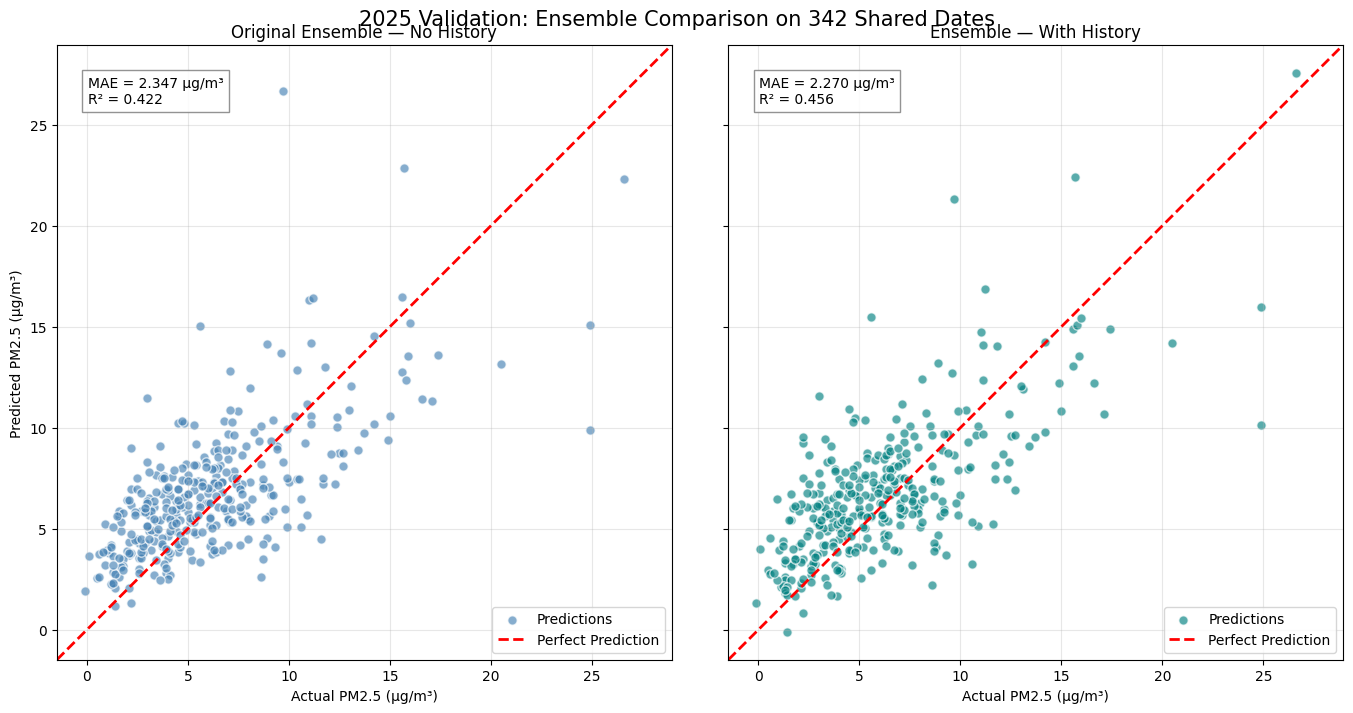

,Approach,Examples,MAE (µg/m³),R²
0,Original Ensemble — No History,342,2.347,0.422
1,Ensemble — With History,342,2.270,0.456


In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# Use identical history-eligible validation dates for both approaches.
plot_data = history_validation.sort_values("target_date")
actual_values = plot_data["pm25_tomorrow"].to_numpy()

# Original ensemble: five inputs, without explicit pollution history.
no_history_predictions = (
    model.predict(plot_data[features])
    + rf_model.predict(plot_data[features])
) / 2

# History ensemble: eight inputs, including recent pollution history.
with_history_predictions = (
    history_lr_model.predict(plot_data[history_features])
    + history_rf_model.predict(plot_data[history_features])
) / 2

# Set matching axis limits for a fair visual comparison.
minimum = min(
    actual_values.min(),
    no_history_predictions.min(),
    with_history_predictions.min()
)
maximum = max(
    actual_values.max(),
    no_history_predictions.max(),
    with_history_predictions.max()
)
padding = max((maximum - minimum) * 0.05, 1)

# Create two graphs with the same scales.
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    sharex=True,
    sharey=True
)

approaches = [
    ("Original Ensemble — No History", no_history_predictions, "steelblue"),
    ("Ensemble — With History", with_history_predictions, "teal")
]

results = []

for ax, (name, predictions, color) in zip(axes, approaches):
    # Calculate performance on the same actual measurements.
    mae = mean_absolute_error(actual_values, predictions)
    r2 = r2_score(actual_values, predictions)

    results.append({
        "Approach": name,
        "Examples": len(plot_data),
        "MAE (µg/m³)": mae,
        "R²": r2
    })

    # Each point represents one next-day prediction.
    ax.scatter(
        actual_values,
        predictions,
        color=color,
        alpha=0.65,
        s=45,
        edgecolors="white",
        label="Predictions"
    )

    # Points on this diagonal are perfect predictions.
    ax.plot(
        [minimum - padding, maximum + padding],
        [minimum - padding, maximum + padding],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Perfect Prediction"
    )

    # Apply identical limits and equal scaling.
    ax.set_xlim(minimum - padding, maximum + padding)
    ax.set_ylim(minimum - padding, maximum + padding)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(name)
    ax.set_xlabel("Actual PM2.5 (µg/m³)")
    ax.grid(True, alpha=0.3)

    # Display error metrics in the upper-left corner.
    ax.text(
        0.05,
        0.95,
        f"MAE = {mae:.3f} µg/m³\nR² = {r2:.3f}",
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="gray"
        )
    )

    ax.legend(loc="lower right")

axes[0].set_ylabel("Predicted PM2.5 (µg/m³)")
fig.suptitle(
    f"2025 Validation: Ensemble Comparison on {len(plot_data)} Shared Dates",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Print a numerical comparison below the plots.
display(pd.DataFrame(results).round(3))

In [42]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use identical validation dates for every approach.
evaluation_data = history_validation.sort_values("target_date")
actual_values = evaluation_data["pm25_tomorrow"].to_numpy()

# Original ensemble: five inputs without explicit pollution history.
ensemble_pred = (
    model.predict(evaluation_data[features])
    + rf_model.predict(evaluation_data[features])
) / 2

# History ensemble: both components use the expanded history inputs.
history_ensemble_pred = (
    history_lr_model.predict(evaluation_data[history_features])
    + history_rf_model.predict(evaluation_data[history_features])
) / 2

# Baseline: tomorrow's pollution equals today's.
baseline_pred = evaluation_data["pm25"].to_numpy()

# Calculate baseline MAE for percentage-improvement comparisons.
baseline_mae = mean_absolute_error(actual_values, baseline_pred)

# Evaluate every approach against the same actual measurements.
predictions = {
    "Persistence baseline": baseline_pred,
    "Original ensemble": ensemble_pred,
    "Ensemble with history": history_ensemble_pred
}

results = []

for name, predicted_values in predictions.items():
    # MAE measures average absolute error.
    mae = mean_absolute_error(actual_values, predicted_values)

    # RMSE gives greater weight to large errors.
    rmse = np.sqrt(
        mean_squared_error(actual_values, predicted_values)
    )

    # R² compares squared error with predicting the period's average.
    r2 = r2_score(actual_values, predicted_values)

    # Positive percentages indicate lower MAE than persistence.
    improvement = (
        (baseline_mae - mae) / baseline_mae * 100
        if baseline_mae > 0 else np.nan
    )

    results.append({
        "Approach": name,
        "Evaluated days": len(actual_values),
        "MAE (µg/m³)": mae,
        "RMSE (µg/m³)": rmse,
        "R²": r2,
        "MAE improvement vs baseline (%)": improvement
    })

print("=== AIRAWARE: 2025 VALIDATION PERFORMANCE ===")
display(pd.DataFrame(results).round(3))

=== AIRAWARE: 2025 VALIDATION PERFORMANCE ===


,Approach,Evaluated days,MAE (µg/m³),RMSE (µg/m³),R²,MAE improvement vs baseline (%)
0,Persistence baseline,342,2.608,3.477,0.256,0.000
1,Original ensemble,342,2.347,3.066,0.422,10.018
2,Ensemble with history,342,2.270,2.974,0.456,12.973


In [35]:
# AirAware export cell
# Run after training in Hackathon.ipynb. Export the held-out validation
# period while developing; leave the test set untouched until final evaluation.
import json
import re
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

MODEL_VERSION = "1.2.0"

# The page builds its labels and input limits from this metadata. Add another
# definition when a later model uses another measurement in `features`.
FEATURE_DEFINITIONS = [
    {"id": "pm25", "label": "Daily average PM2.5", "unit": "µg/m³", "min": 0},
    {"id": "temperature_c", "label": "Temperature", "unit": "°C"},
    {"id": "humidity_pct", "label": "Relative humidity", "unit": "%", "min": 0, "max": 100},
    {"id": "precipitation_mm", "label": "Precipitation", "unit": "mm", "min": 0},
    {"id": "wind_speed_ms", "label": "Wind speed", "unit": "m/s", "min": 0},
]


def _num(value, digits=12):
    return None if pd.isna(value) else round(float(value), digits)


def _day(value):
    return pd.Timestamp(value).strftime("%Y-%m-%d")


def _period(frame):
    return {
        "start": _day(frame["target_date"].min()),
        "end": _day(frame["target_date"].max()),
        "examples": int(len(frame)),
    }


# Register models here. Every predictor receives a DataFrame and returns one
# next-day PM2.5 value per row. Models all use the same held-out examples.
# `linear` inference runs from exported weights in a standalone browser.
# `colab` inference uses the live notebook callback for edited/custom inputs;
# its historical exported predictions remain usable outside Colab.
MODEL_REGISTRY = [
    {
        "id": "persistence",
        "name": "Persistence baseline",
        "kind": "baseline",
        "version": MODEL_VERSION,
        "features": ["pm25"],
        "training_period": None,
        "inference": {"type": "persistence", "feature": "pm25"},
        "predict": lambda frame: frame["pm25"].to_numpy(dtype=float),
    },
    {
        "id": "linear_regression",
        "name": "Linear Regression",
        "kind": "model",
        "version": MODEL_VERSION,
        "features": list(features),
        "training_period": _period(train_df),
        "inference": {
            "type": "linear",
            "intercept": _num(model.intercept_),
            "coefficients": {
                f: _num(c) for f, c in zip(features, np.asarray(model.coef_).ravel())
            },
        },
        "predict": lambda frame: model.predict(frame[features]),
    },
]

# To add any fitted sklearn-style estimator, append an entry before exporting:
# MODEL_REGISTRY.append({
#     "id": "random_forest", "name": "Random Forest", "kind": "model",
#     "version": MODEL_VERSION, "features": list(features),
#     "training_period": _period(train_df), "inference": {"type": "colab"},
#     "predict": lambda frame: forest_model.predict(frame[features]),
# })
# Train and choose models on training/validation data before final testing.
DEFAULT_MODEL_ID = "linear_regression"
BASELINE_MODEL_ID = "persistence"

registry_ids = [entry["id"] for entry in MODEL_REGISTRY]
if len(registry_ids) != len(set(registry_ids)) or any(
    not re.fullmatch(r"[a-z][a-z0-9_]*", model_id)
    or model_id in {"date", "target_date", "actual"}
    for model_id in registry_ids
):
    raise ValueError("Every registered model needs a unique, non-reserved lowercase ID.")
if DEFAULT_MODEL_ID not in registry_ids or BASELINE_MODEL_ID not in registry_ids:
    raise ValueError("The default and baseline model IDs must be in MODEL_REGISTRY.")

# Do not add test_df until the model and any decision rules are finalized.
eval_sets = {"validation": validation_df}
model_outputs = {entry["id"]: entry["predict"] for entry in MODEL_REGISTRY}
predictions = {}
mae = {name: {} for name in model_outputs}

for split, frame in eval_sets.items():
    block = {
        "date": [_day(d) for d in frame["date"]],
        "target_date": [_day(d) for d in frame["target_date"]],
        "actual": [_num(v) for v in frame["pm25_tomorrow"]],
    }
    for name, predict in model_outputs.items():
        values = np.asarray(predict(frame), dtype=float).reshape(-1)
        if len(values) != len(frame) or not np.isfinite(values).all():
            raise ValueError(f"{name} must return one finite prediction per evaluation row.")
        block[name] = [_num(v) for v in values]
        mae[name][split] = round(
            float(mean_absolute_error(frame["pm25_tomorrow"], values)), 3
        )
    predictions[split] = block

# Keep existing intercept/coefficients fields for older schema-1 viewers while
# declaring how each model can run through the new `inference` field.
models = []
for entry in MODEL_REGISTRY:
    metadata = {key: value for key, value in entry.items() if key != "predict"}
    metadata["mae"] = mae[entry["id"]]
    if entry["inference"]["type"] == "linear":
        metadata["intercept"] = entry["inference"]["intercept"]
        metadata["coefficients"] = entry["inference"]["coefficients"]
    models.append(metadata)

required_features = list(dict.fromkeys(
    ["pm25"] + [feature for entry in MODEL_REGISTRY for feature in entry["features"]]
))
definitions = {entry["id"]: entry for entry in FEATURE_DEFINITIONS}
if any(feature not in combined.columns for feature in required_features):
    raise ValueError("A model requests an input column that is missing from combined.")

methods = []
if {"method_code", "method_description"}.issubset(combined.columns):
    for _, row in combined[["method_code", "method_description"]].dropna().drop_duplicates().iterrows():
        methods.append({"code": str(int(row["method_code"])), "description": str(row["method_description"])})

export = {
    "schema_version": "1",
    "demo": False,
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "units": "µg/m³",
    "default_model_id": DEFAULT_MODEL_ID,
    "baseline_model_id": BASELINE_MODEL_ID,
    "feature_definitions": [
        definitions.get(feature, {"id": feature, "label": feature.replace("_", " ").capitalize(), "unit": ""})
        for feature in required_features
    ],
    "location": {
        "name": "Rutgers University",
        "state": "NJ",
        "site_id": "340230011",
        "poc": "3",
        "methods": methods,
    },
    "sources": {
        "pollution": "US EPA daily PM2.5 (AQS, with preliminary AirNow records)",
        "weather": "Open-Meteo historical weather archive",
    },
    # Keep input precision: an unchanged example must use the same measurements
    # as the notebook. Never round the form's source inputs for presentation.
    "daily": {
        "date": [_day(d) for d in combined["date"]],
        **{f: [_num(v) for v in combined[f]] for f in required_features},
    },
    "splits": {"train": _period(train_df), **{s: _period(f) for s, f in eval_sets.items()}},
    "models": models,
    "predictions": predictions,
}

out_path = folder / "airaware_export.json"
with open(out_path, "w", encoding="utf-8") as fh:
    json.dump(export, fh, ensure_ascii=False, allow_nan=False, separators=(",", ":"))

print("Wrote", out_path)
print("Validation MAE:", mae)
print("Test results are not evaluated or exported.")


Wrote /content/drive/MyDrive/veritas AI project/airaware_export.json
Validation MAE: {'persistence': {'validation': 2.604}, 'linear_regression': {'validation': 2.41}}
Test results are not evaluated or exported.


In [36]:
# AirAware viewer cell
# Run AFTER the export cell. Upload index.html to the same Drive folder
# as your CSV files. The single HTML page also works outside Colab.
import html
import json
import math
from pathlib import Path
from IPython.display import HTML, display

# Fallback definition if the notebook kernel was restarted and 'folder' was cleared
if "folder" not in globals():
    folder = Path("/content/drive/MyDrive/veritas AI project")

try:
    page = (folder / "index.html").read_text(encoding="utf-8")
    data = json.loads((folder / "airaware_export.json").read_text(encoding="utf-8"))

    # Arbitrary registered models can predict edited/custom inputs in Colab.
    # Outside Colab, the page still uses exported historical predictions and any
    # browser-compatible inference weights supplied by the export.
    colab_ready = False
    try:
        from google.colab import output
        from IPython.display import JSON
        import numpy as np
        import pandas as pd

        if "MODEL_REGISTRY" in globals():
            _airaware_registry = {entry["id"]: entry for entry in MODEL_REGISTRY}
            _airaware_limits = {entry["id"]: entry for entry in data.get("feature_definitions", [])}
            _airaware_export_id = data.get("generated_at")

            def _airaware_predict(model_id, values):
                if model_id not in _airaware_registry:
                    raise ValueError("The requested model is not registered in this notebook.")
                if not isinstance(values, dict):
                    raise ValueError("Prediction inputs must be an object of measurements.")
                entry = _airaware_registry[model_id]
                inputs = {}
                for feature in entry["features"]:
                    value = values.get(feature)
                    if isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value):
                        raise ValueError(f"{feature} must be a finite number.")
                    limits = _airaware_limits.get(feature, {})
                    if ("min" in limits and value < limits["min"]) or ("max" in limits and value > limits["max"]):
                        raise ValueError(f"{feature} is outside its allowed range.")
                    inputs[feature] = float(value)
                frame = pd.DataFrame([inputs], columns=entry["features"])
                result = np.asarray(entry["predict"](frame), dtype=float).reshape(-1)
                if len(result) != 1 or not math.isfinite(float(result[0])):
                    raise ValueError("The model did not return one finite prediction.")
                return JSON({
                    "model_id": model_id,
                    "prediction": float(result[0]),
                    "generated_at": _airaware_export_id,
                })

            output.register_callback("airaware.predict", _airaware_predict)
            colab_ready = True
    except ImportError:
        pass

    # Escape '<' so strings in the export cannot close the script element.
    payload = json.dumps(data, ensure_ascii=False, allow_nan=False).replace("<", "\\u003c")
    inject = (
        "<script>window.AIRAWARE_EXPORT=" + payload
        + ";window.AIRAWARE_COLAB=" + json.dumps(colab_ready) + ";</script>"
    )
    page = page.replace("<body>", "<body>" + inject, 1)

    display(HTML(
        '<iframe title="AirAware historical PM2.5 forecasting prototype" srcdoc="'
        + html.escape(page, quote=True)
        + '" style="width:100%;height:950px;border:0;border-radius:12px"></iframe>'
    ))

except FileNotFoundError as e:
    print(f"Error: {e}")
    print("\nPlease verify that:")
    print("1. Your Google Drive is mounted (run the first cell in the notebook).")
    print(f"2. The files 'index.html' and 'airaware_export.json' exist in:")
    print(f"   {folder}/")

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
